# PiWD - PS5

Cel zajęć: Nauka podstawowego wizualizowania danych, zrozumienie podstawowych funkcjonalności matplotlib


> Data visualization is the language of decision making. Good charts effectively convey information. Great charts enable, inform, and improve decision making." 
— Dante Vitagliano 

-----
## Przykłady

In [2]:
import pandas as pd 
import numpy as np
hd_df = pd.read_csv("dane/heart_disease.csv")
hd_df

,Gender,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,Heart_ stroke
0,Male,39,postgraduate,0,0.0,0.0,no,0,0,195.0,106.0,70.0,26.97,80.0,77.0,No
1,Female,46,primaryschool,0,0.0,0.0,no,0,0,250.0,121.0,81.0,28.73,95.0,76.0,No
2,Male,48,uneducated,1,20.0,0.0,no,0,0,245.0,127.5,80.0,25.34,75.0,70.0,No
3,Female,61,graduate,1,30.0,0.0,no,1,0,225.0,150.0,95.0,28.58,65.0,103.0,yes
4,Female,46,graduate,1,23.0,0.0,no,0,0,285.0,130.0,84.0,23.10,85.0,85.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,Male,50,uneducated,1,1.0,0.0,no,1,0,313.0,179.0,92.0,25.97,66.0,86.0,yes
4234,Male,51,graduate,1,43.0,0.0,no,0,0,207.0,126.5,80.0,19.71,65.0,68.0,No
4235,Female,48,primaryschool,1,20.0,NaN,no,0,0,248.0,131.0,72.0,22.00,84.0,86.0,No
4236,Female,44,uneducated,1,15.0,0.0,no,0,0,210.0,126.5,87.0,19.16,86.0,NaN,No


### Wykres liniowy
odajmy najpierw grupy wiekowe i wyliczmy dla nich niskie i wysokie ciśnienie w odzielnej ramce danych.

In [3]:
hd_df["Age Group"] = ( np.floor(hd_df["age"]/5.0)*5).astype("int")

df = hd_df.groupby(["Age Group"])[["sysBP",	"diaBP"]].mean().reset_index()
df

,Age Group,sysBP,diaBP
0,30,114.375000,73.500000
1,35,120.442561,78.144068
2,40,124.539655,80.663218
3,45,129.531013,82.840506
4,50,135.016289,85.011331
5,55,139.239234,85.039075
6,60,145.286807,85.659656
7,65,149.345455,85.506061
8,70,139.500000,88.500000


In [4]:
import matplotlib.pyplot as plt

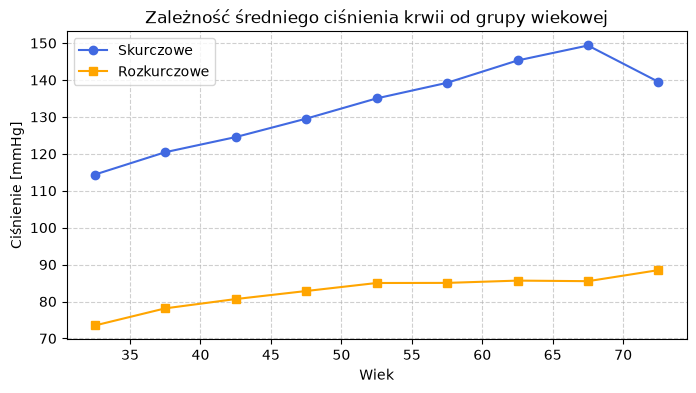

In [5]:
plt.figure(figsize=(8, 4))

plt.plot(df['Age Group']+2.5, df["sysBP"], marker='o', label='Skurczowe', color='royalblue')
plt.plot(df['Age Group']+2.5, df["diaBP"], marker='s', label='Rozkurczowe', color='orange')

plt.title('Zależność średniego ciśnienia krwii od grupy wiekowej')
plt.xlabel('Wiek')
plt.ylabel('Ciśnienie [mmHg]')
plt.legend() 
plt.grid(True, linestyle='--', alpha=0.6) 

plt.show()

### Dostępne markery

Poniżej macie Państwo wymienione wszystkie dotępne domyślnie markery w matplotlib. Oprócz tych można też definiować własne, jednak poprzestańmy na tych.

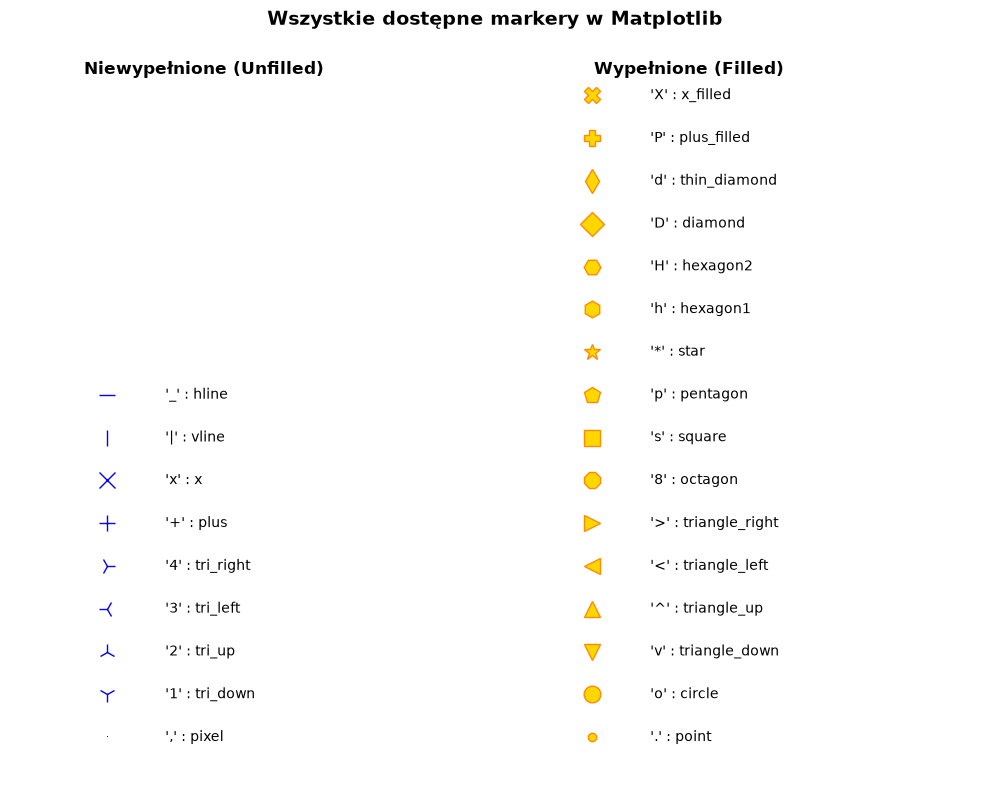

In [6]:
from matplotlib.lines import Line2D

all_markers = {k: v for k, v in Line2D.markers.items() if isinstance(k, str) and k != '' and v != 'nothing'}

filled_symbols = set(Line2D.filled_markers)
filled_markers = {k: v for k, v in all_markers.items() if k in filled_symbols}
unfilled_markers = {k: v for k, v in all_markers.items() if k not in filled_symbols}

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(-0.5, 4.5)
ax.set_ylim(-1, max(len(unfilled_markers), len(filled_markers)))

ax.text(0.5, max(len(unfilled_markers), len(filled_markers)) - 0.5, "Niewypełnione (Unfilled)", fontsize=12, weight='bold', ha='center')
for i, (symbol, description) in enumerate(unfilled_markers.items()):
    ax.plot(0, i, marker=symbol, markersize=12, color='blue')
    ax.text(0.3, i, f"'{symbol}' : {description}", va='center', fontsize=10)

ax.text(3.0, max(len(unfilled_markers), len(filled_markers)) - 0.5, "Wypełnione (Filled)", fontsize=12, weight='bold', ha='center')
for i, (symbol, description) in enumerate(filled_markers.items()):
    ax.plot(2.5, i, marker=symbol, markersize=12, color='darkorange', markerfacecolor='gold', markeredgecolor='darkorange')
    ax.text(2.8, i, f"'{symbol}' : {description}", va='center', fontsize=10)

ax.set_axis_off()
plt.title("Wszystkie dostępne markery w Matplotlib", fontsize=14, pad=20, weight='bold')
plt.tight_layout()
plt.show()

### Wykres punktowy




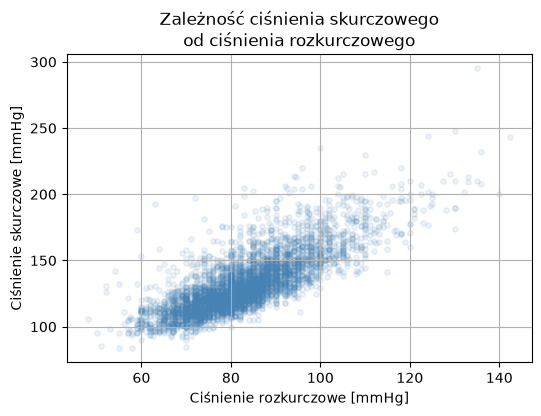

In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(hd_df['diaBP'], hd_df['sysBP'], color='steelblue', s=15, alpha=0.1)

plt.title('Zależność ciśnienia skurczowego\nod ciśnienia rozkurczowego')
plt.xlabel('Ciśnienie rozkurczowe [mmHg]')
plt.ylabel('Ciśnienie skurczowe [mmHg]')
plt.grid(True)

plt.show()

## Kołowy

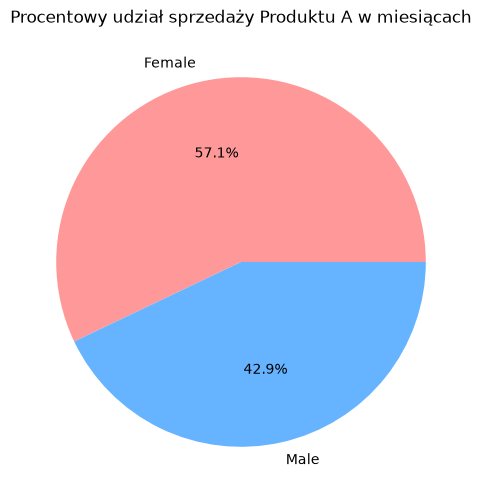

In [8]:
plt.figure(figsize=(6, 6))

# Wykres kołowy wymaga podania danych i etykiet
plt.pie(hd_df['Gender'].value_counts(), labels=hd_df['Gender'].value_counts().index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])

plt.title('Procentowy udział sprzedaży Produktu A w miesiącach')
plt.show()

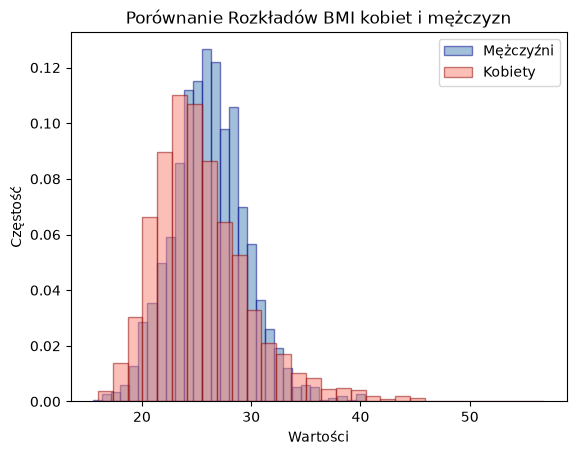

In [9]:
#plt.hist(hd_df["BMI"], alpha=0.5, label=hd_df["Gender"])
plt.hist(hd_df.loc[hd_df["Gender"]=="Male", "BMI"], 
         bins=30, #liczba przedziałów (kubełków) na które dzielimy przedział danych
         alpha=0.5, # przeźroczystość
         label='Mężczyźni', # etykieta w legendzie
         color='steelblue', 
         edgecolor='darkblue', 
         density=True) # pzedstawiaj znormalizowane do procentów wykresy - ważne przy niezbalansowanych danych - pozwala łatwiej porównać rozkłady
plt.hist(hd_df.loc[hd_df["Gender"]=="Female", "BMI"], 
         bins=30, 
         alpha=0.5, 
         label='Kobiety', 
         color='salmon', 
         edgecolor='darkred', 
         density=True)

plt.title('Porównanie Rozkładów BMI kobiet i mężczyzn')
plt.xlabel('Wartości')
plt.ylabel('Częstość')
plt.legend()  # Pokazuje legendę na podstawie parametru 'label'
plt.show()

proszę zwrócić uwagę na nierówne podziały na kubełki jednego i drugiego histogramu

### Pudełkowy

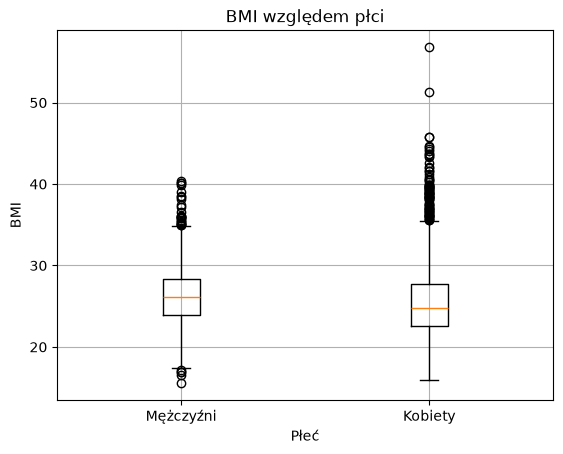

In [21]:
plt.boxplot([hd_df.loc[hd_df["Gender"]=="Male", "BMI"].dropna().tolist(), \
             hd_df.loc[hd_df["Gender"]=="Female", "BMI"].dropna().tolist()],
             tick_labels=["Mężczyźni", "Kobiety"])

plt.title("BMI względem płci")
plt.xlabel("Płeć")
plt.ylabel("BMI")
plt.grid(True)
plt.show()

### Złożenie wykresów

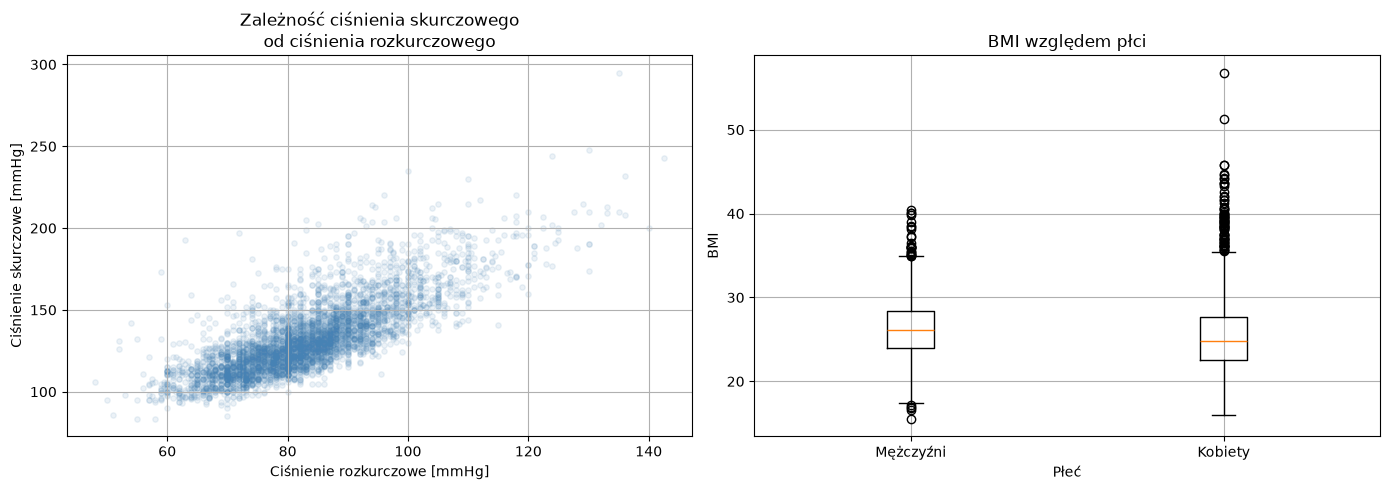

In [11]:
# Tworzymy siatkę: 1 wiersz, 2 kolumny i rozmiar płótna
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Pierwszy wykres (lewy) - Sprzedaż
ax1.scatter(hd_df['diaBP'], hd_df['sysBP'], color='steelblue', s=15, alpha=0.1)

ax1.set_title('Zależność ciśnienia skurczowego\nod ciśnienia rozkurczowego')
ax1.set_xlabel('Ciśnienie rozkurczowe [mmHg]')
ax1.set_ylabel('Ciśnienie skurczowe [mmHg]')
ax1.grid(True)


ax2.boxplot([hd_df.loc[hd_df["Gender"]=="Male", "BMI"].dropna().tolist(), \
             hd_df.loc[hd_df["Gender"]=="Female", "BMI"].dropna().tolist()],
             tick_labels=["Mężczyźni", "Kobiety"])

ax2.set_title("BMI względem płci")
ax2.set_xlabel("Płeć")
ax2.set_ylabel("BMI")
ax2.grid(True)

# Automatyczne dopasowanie odstępów
plt.tight_layout()
plt.show()

### Różne dodatki do wykresu w siatce 2 na 2

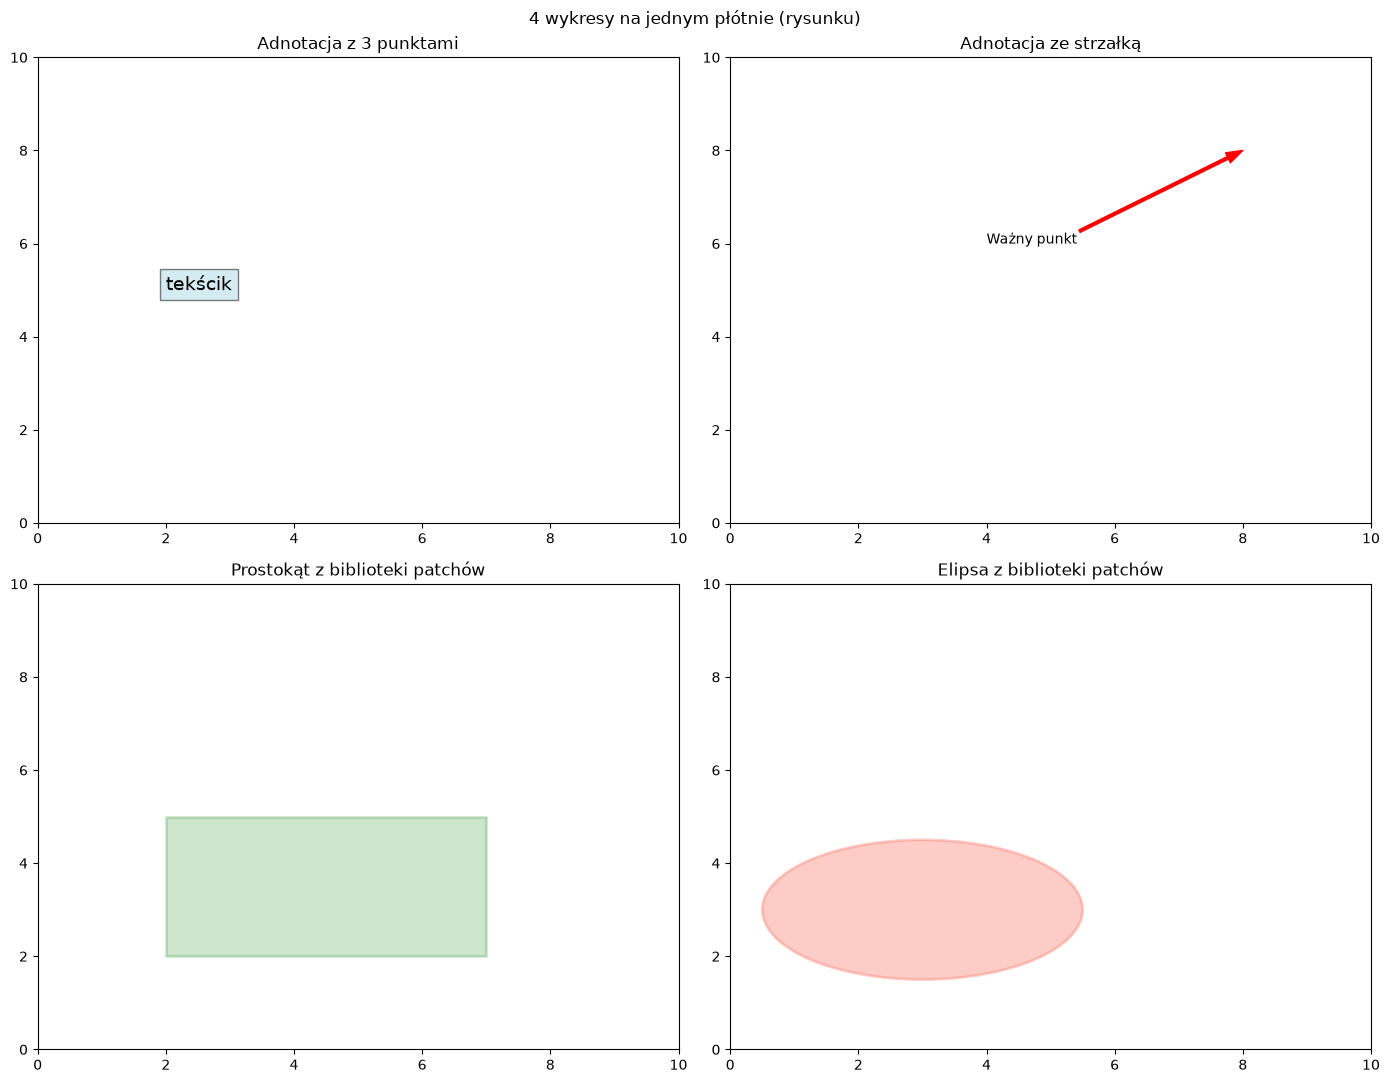

In [12]:
# Tworzymy siatkę: 2 wiersze, 2 kolumny i rozmiar płótna
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

axes[0,0].set_xlim(0, 10)
axes[0,0].set_ylim(0, 10)
tekst = "tekścik"
axes[0,0].text(2, 5, tekst, fontsize=14, bbox=dict(facecolor='lightblue', alpha=0.5))
axes[0,0].set_title("Adnotacja z 3 punktami")


axes[0,1].set_xlim(0, 10)
axes[0,1].set_ylim(0, 10)
axes[0,1].annotate('Ważny punkt', # Dodanie strzałki wskazującej punkt (8, 8) z tekstem opisującym
            xy=(8, 8),      # Grot strzałki (cel)
            xytext=(4, 6),  # Początek tekstu i strzałki
            arrowprops=dict(facecolor='red',  width=2, headwidth=8, edgecolor='red'))
axes[0,1].set_title("Adnotacja ze strzałką")

import matplotlib.patches as patches

axes[1,0].set_xlim(0, 10)
axes[1,0].set_ylim(0, 10)
prostokat = patches.Rectangle((2, 2), 5, 3,  #lewy dolny róg (x,y), szerokość i wysokość
                              linewidth=2, 
                              edgecolor='green', 
                              facecolor='green', 
                              alpha=0.2) 
axes[1,0].add_patch(prostokat)
axes[1,0].set_title("Prostokąt z biblioteki patchów")


axes[1,1].set_xlim(0, 10)
axes[1,1].set_ylim(0, 10)
elipsa = patches.Ellipse((3, 3), 5, 3, #środek (x,y), szerokość i wysokość
                         linewidth=2, 
                         edgecolor='salmon', 
                         facecolor='salmon', 
                         alpha=0.4)
axes[1,1].add_patch(elipsa)
axes[1,1].set_title("Elipsa z biblioteki patchów")

plt.suptitle("4 wykresy na jednym płótnie (rysunku)") # tytuł całego rysunku (suptitle!)
plt.tight_layout()
plt.show()

Jako, że do wykresów odwołujemy się przez indeksy, możemy po nich iterować pętlami for

# Zadania samodzielne:

Wykonaj je za pomocą czystego matplotlib (jak wyżej w notatniku) - nie bezpośrednio z obiektów pandas (dataframe ma odpowiednie predefiniowane metody w odpowiednich polach).

1. Proszę wykonać wykres rozrzutu całego cholesterolu względem wieku. Ustaw odpowiednie tytuły osi i całego rysunku. Wykorzystaj kwadratowy marker (punkty w kształcie kwadratów)
1. Wykonaj na jednym wykresie (tak by dało się je porównać jak w przykładzie) wykresy pudełkowe BMI dla grup pacjentów o różnym poziomie wykształcenia
1. Wykonaj wykres kołowy dla poziomów wykształcenia. Dobierz własny zestaw kolorów (ściąga z nazwami predefiniowanych kolorów https://matplotlib.org/stable/gallery/color/named_colors.html)
1. Uzupełnij przykładowy (wyżej już wykonany) wykres rozrzutu o strzałkę wskazującą położenie idealnego (książkowego ciśnienia rozkurczowego i skurczowego:
(sysBR=120, diaBP=80)) (annotate z przykładu) - ustaw odpowiedni tekst i współrzędne, zaproponuj inny kolor.
1. Na jednym rysunku wykonaj dwa histogramy obok siebie (subplots) dla całego cholesterolu kobiet i mężczyzn. Co trzeba zmienić aby wykresy były jeden pod drugim?


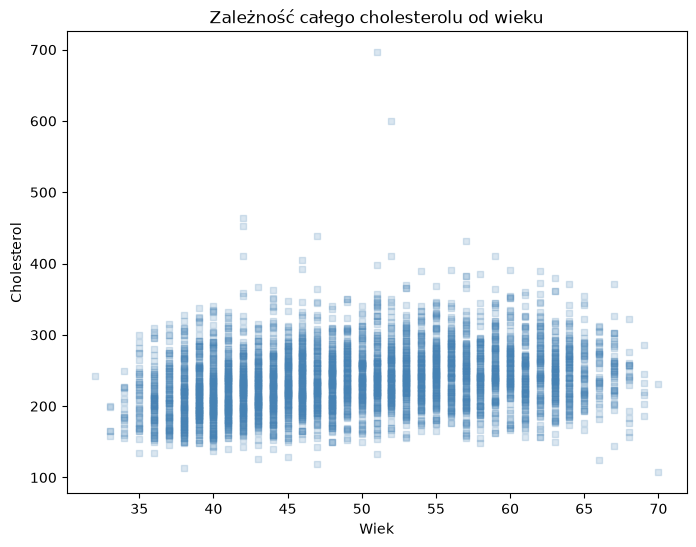

In [33]:
# 1. Proszę wykonać wykres rozrzutu całego cholesterolu względem wieku. Ustaw odpowiednie tytuły osi i całego rysunku. Wykorzystaj kwadratowy marker (punkty w kształcie kwadratów)

plt.figure(figsize=(8, 6))
plt.scatter(hd_df['age'], hd_df['totChol'], color='steelblue', marker='s', s=15, alpha=0.2)

plt.title("Zależność całego cholesterolu od wieku")
plt.xlabel("Wiek")
plt.ylabel("Cholesterol")
plt.show()

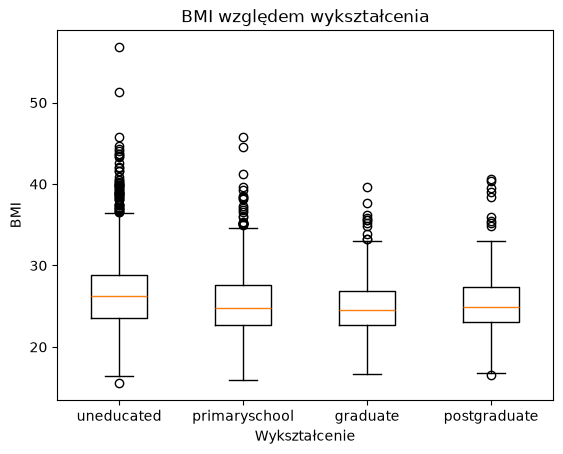

In [ ]:
# 2. Wykonaj na jednym wykresie (tak by dało się je porównać jak w przykładzie) wykresy pudełkowe BMI dla grup pacjentów o różnym poziomie wykształcenia

education = hd_df["education"].value_counts().index
bmi_to_education = [hd_df.loc[hd_df["education"]==e, "BMI"].dropna().tolist() for e in education]

plt.boxplot(bmi_to_education, tick_labels=education)

plt.title("BMI względem wykształcenia")
plt.ylabel("BMI")
plt.xlabel("Wykształcenie")
plt.show()

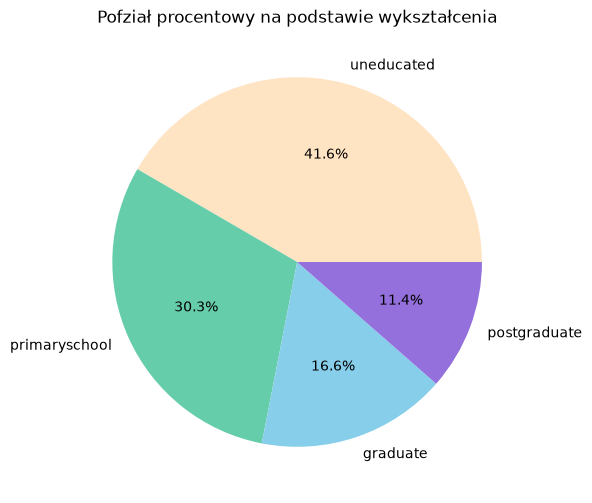

In [ ]:
# 3. Wykonaj wykres kołowy dla poziomów wykształcenia. Dobierz własny zestaw kolorów 
# (ściąga z nazwami predefiniowanych kolorów https://matplotlib.org/stable/gallery/color/named_colors.html)

plt.figure(figsize=(6, 6))

plt.pie(hd_df['education'].value_counts(), labels=hd_df['education'].value_counts().index, autopct='%1.1f%%', colors=['bisque','mediumaquamarine', 'skyblue', 'mediumpurple'])

plt.title('Pofział procentowy na podstawie wykształcenia')
plt.show()

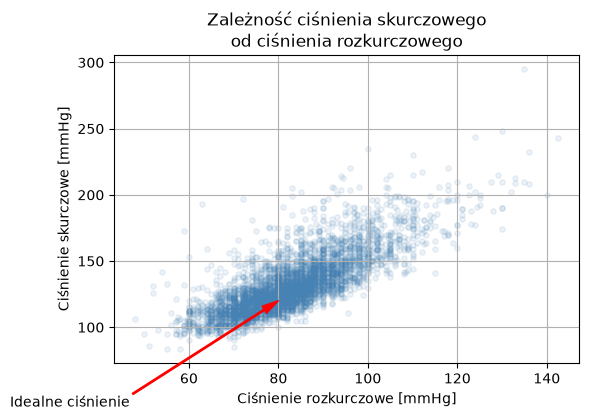

In [ ]:
# 4. Uzupełnij przykładowy (wyżej już wykonany) wykres rozrzutu o strzałkę wskazującą położenie idealnego (książkowego ciśnienia rozkurczowego i skurczowego:
# (sysBR=120, diaBP=80)) (annotate z przykładu) - ustaw odpowiedni tekst i współrzędne, zaproponuj inny kolor.

plt.figure(figsize=(6, 4))

plt.scatter(hd_df['diaBP'], hd_df['sysBP'], color='steelblue', s=15, alpha=0.1)

plt.title('Zależność ciśnienia skurczowego\nod ciśnienia rozkurczowego')
plt.xlabel('Ciśnienie rozkurczowe [mmHg]')
plt.ylabel('Ciśnienie skurczowe [mmHg]')
plt.annotate('Idealne ciśnienie',
            xy=(80, 120),
            xytext=(20, 40),
            arrowprops=dict(facecolor='red',  width=1, headwidth=6, edgecolor='red'))
plt.grid(True)
plt.show()

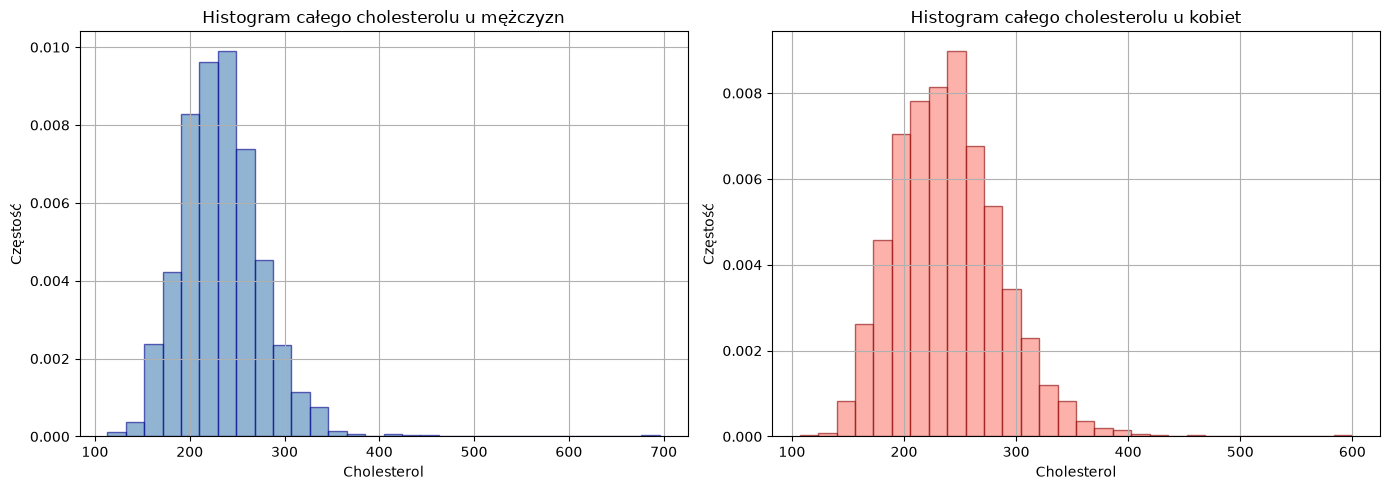

In [63]:
# 5. Na jednym rysunku wykonaj dwa histogramy obok siebie (subplots) dla całego cholesterolu kobiet i mężczyzn. Co trzeba zmienić aby wykresy były jeden pod drugim?

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(hd_df.loc[hd_df["Gender"]=="Male", "totChol"], 
         bins=30,
         alpha=0.6,
         label='Mężczyźni',
         color='steelblue', 
         edgecolor='darkblue', 
         density=True)

ax1.set_title('Histogram całego cholesterolu u mężczyzn')
ax1.set_xlabel('Cholesterol')
ax1.set_ylabel('Częstość')
ax1.grid(True)

ax2.hist(hd_df.loc[hd_df["Gender"]=="Female", "totChol"], 
         bins=30,
         alpha=0.6,
         label='Kobiety',
         color='salmon', 
         edgecolor='darkred', 
         density=True)

ax2.set_title('Histogram całego cholesterolu u kobiet')
ax2.set_xlabel('Cholesterol')
ax2.set_ylabel('Częstość')
ax2.grid(True)

plt.tight_layout()
plt.show()



Aby wykresy były jeden pod drugim należy zmienić wartości w plt.subplots():

* plt.subplots(1, 2, figsize=(14, 5)) - wykresy obok siebie
* plt.subplots(2, 1, figsize=(10, 14)) - wykresy jeden pod drugim